# Hyper-Kvasir: exploratory data analysis
Labelled GI-endoscopy images. Goal: understand classes, organs, and how balanced the dataset is.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', context='notebook', palette='deep', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

In [4]:
df = pd.read_csv('./data/hyper-kvasir/image-labels.csv')
df = df.rename(columns={'Video file': 'id', 'Organ': 'organ', 'Finding': 'finding', 'Classification': 'category'})
df.head()

,id,organ,finding,category
0,000e3fee-7f5c-4819-9f9c-4c983b68888a,Lower GI,cecum,anatomical-landmarks
1,001a41c2-2a5d-40b1-8fd5-b5f2f292277b,Lower GI,cecum,anatomical-landmarks
2,006af0aa-2044-4477-964d-10d9e043fb78,Lower GI,cecum,anatomical-landmarks
3,00832522-ab8e-4b98-bfce-93a777929571,Lower GI,cecum,anatomical-landmarks
4,012ab888-64e6-4361-9745-f52b4a03ba75,Lower GI,cecum,anatomical-landmarks


## Overview

In [5]:
print(f'Rows: {len(df):,}')
print(f'Unique ids: {df.id.nunique():,}')
print(f'Missing values: {df.isna().sum().sum()}')
print(f'Organs: {df.organ.nunique()}, categories: {df.category.nunique()}, findings (classes): {df.finding.nunique()}')
df.nunique()

Rows: 10,662
Unique ids: 10,662
Missing values: 0
Organs: 2, categories: 4, findings (classes): 23


id          10662
organ           2
finding        23
category        4
dtype: int64

**What does each row represent?** The column is called `Video file`, but all 10,662 values are unique (one per row), so each row is a single labelled *frame/image*, identified by a UUID, rather than a whole video. The hierarchy is **Organ → Category → Finding**, and `Finding` is the 23-class label.

## Organs

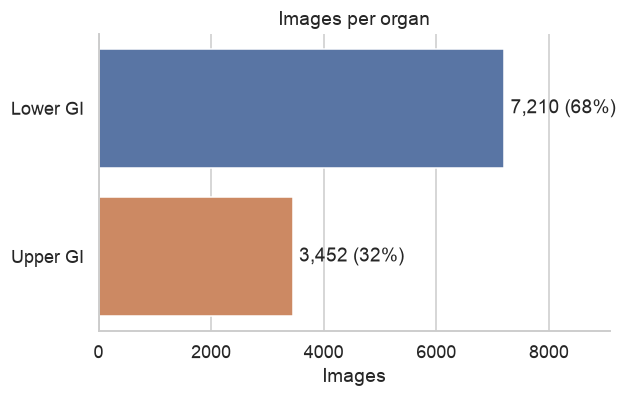

In [6]:
order = df.organ.value_counts().index
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.countplot(data=df, y='organ', order=order, hue='organ', legend=False, ax=ax)
for c in ax.containers:
    ax.bar_label(c, labels=[f'{int(v):,} ({v/len(df):.0%})' for v in c.datavalues], padding=4)
ax.set(title='Images per organ', xlabel='Images', ylabel='')
ax.set_xlim(0, ax.get_xlim()[1] * 1.2)
plt.show()

## Categories

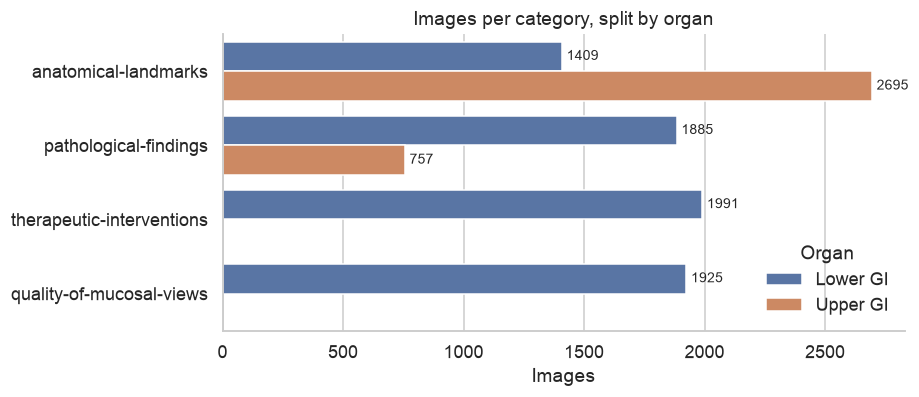

In [7]:
order = df.category.value_counts().index
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.countplot(data=df, y='category', order=order, hue='organ', ax=ax)
for c in ax.containers:
    ax.bar_label(c, padding=3, fontsize=9)
ax.set(title='Images per category, split by organ', xlabel='Images', ylabel='')
ax.legend(title='Organ', frameon=False)
plt.show()

## Findings (the 23 classes)

In [8]:
counts = (df.groupby(['finding', 'organ', 'category']).size().rename('n').reset_index()
            .sort_values('n', ascending=False))
counts.assign(share=lambda d: (d.n / d.n.sum()).round(3)).reset_index(drop=True)

,finding,organ,category,n,share
0,bbps-2-3,Lower GI,quality-of-mucosal-views,1148,0.108
1,polyps,Lower GI,pathological-findings,1028,0.096
2,cecum,Lower GI,anatomical-landmarks,1009,0.095
3,dyed-lifted-polyps,Lower GI,therapeutic-interventions,1002,0.094
4,pylorus,Upper GI,anatomical-landmarks,999,0.094
5,dyed-resection-margins,Lower GI,therapeutic-interventions,989,0.093
6,z-line,Upper GI,anatomical-landmarks,932,0.087
7,retroflex-stomach,Upper GI,anatomical-landmarks,764,0.072
8,bbps-0-1,Lower GI,quality-of-mucosal-views,646,0.061
9,ulcerative-colitis-grade-2,Lower GI,pathological-findings,443,0.042


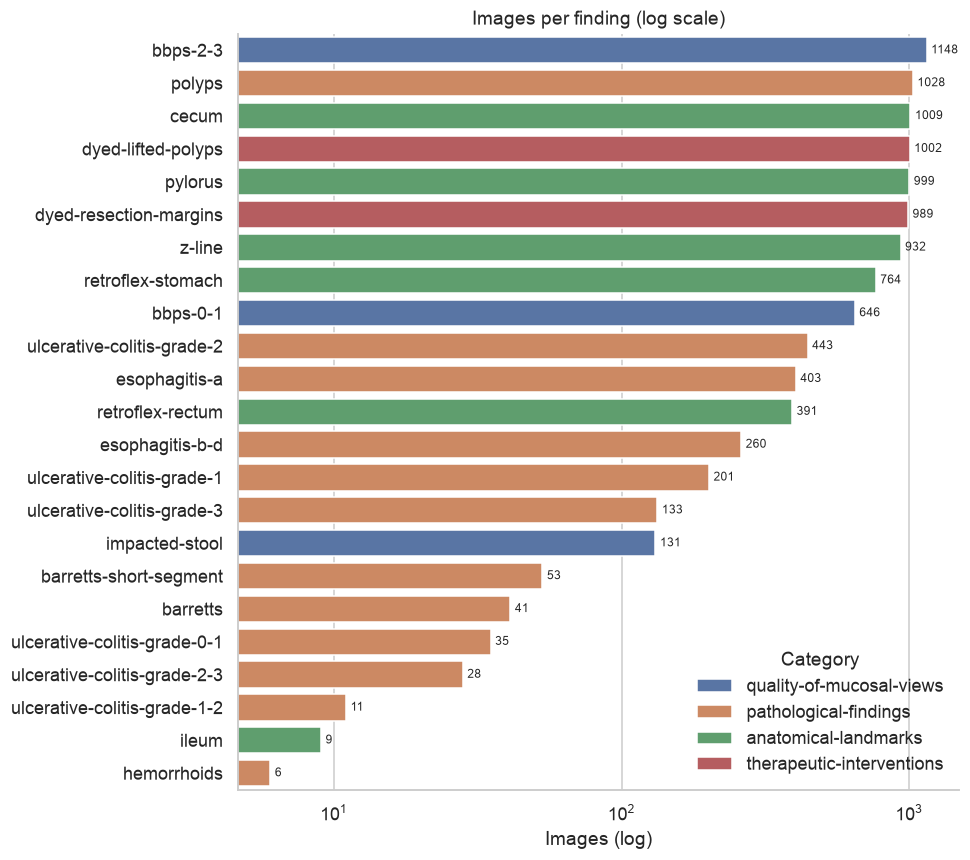

In [9]:
fig, ax = plt.subplots(figsize=(9, 8))
sns.barplot(data=counts, y='finding', x='n', hue='category', dodge=False, ax=ax)
for c in ax.containers:
    ax.bar_label(c, padding=3, fontsize=8)
ax.set(title='Images per finding (log scale)', xlabel='Images (log)', ylabel='', xscale='log')
ax.legend(title='Category', frameon=False, loc='lower right')
plt.tight_layout()
plt.show()

## Organ × category × finding

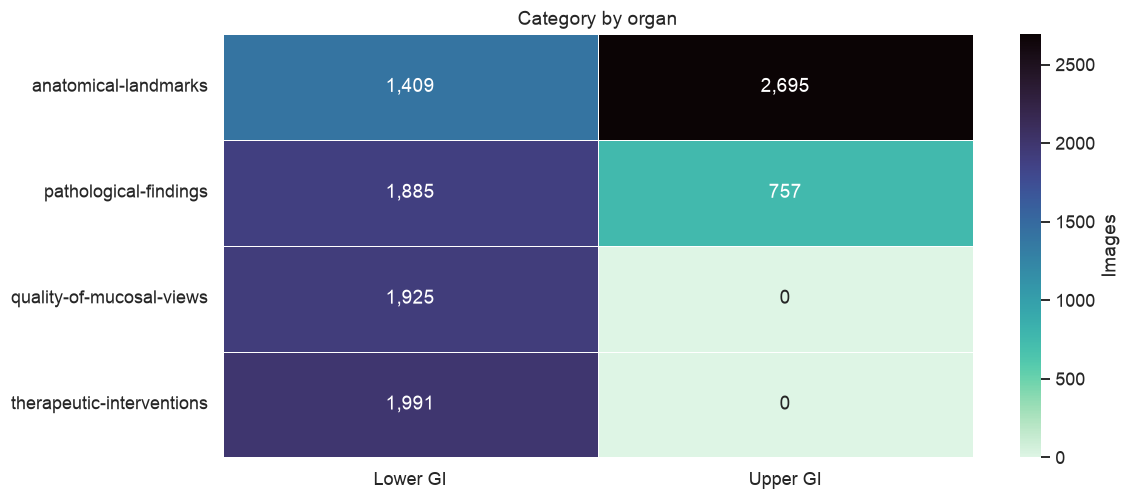

In [10]:
fig, ax = plt.subplots(figsize=(11, 5))
tab = pd.crosstab(df.category, df.organ)
sns.heatmap(tab, annot=True, fmt=',d', cmap='mako_r', linewidths=.5, cbar_kws={'label': 'Images'}, ax=ax)
ax.set(title='Category by organ', xlabel='', ylabel='')
plt.show()

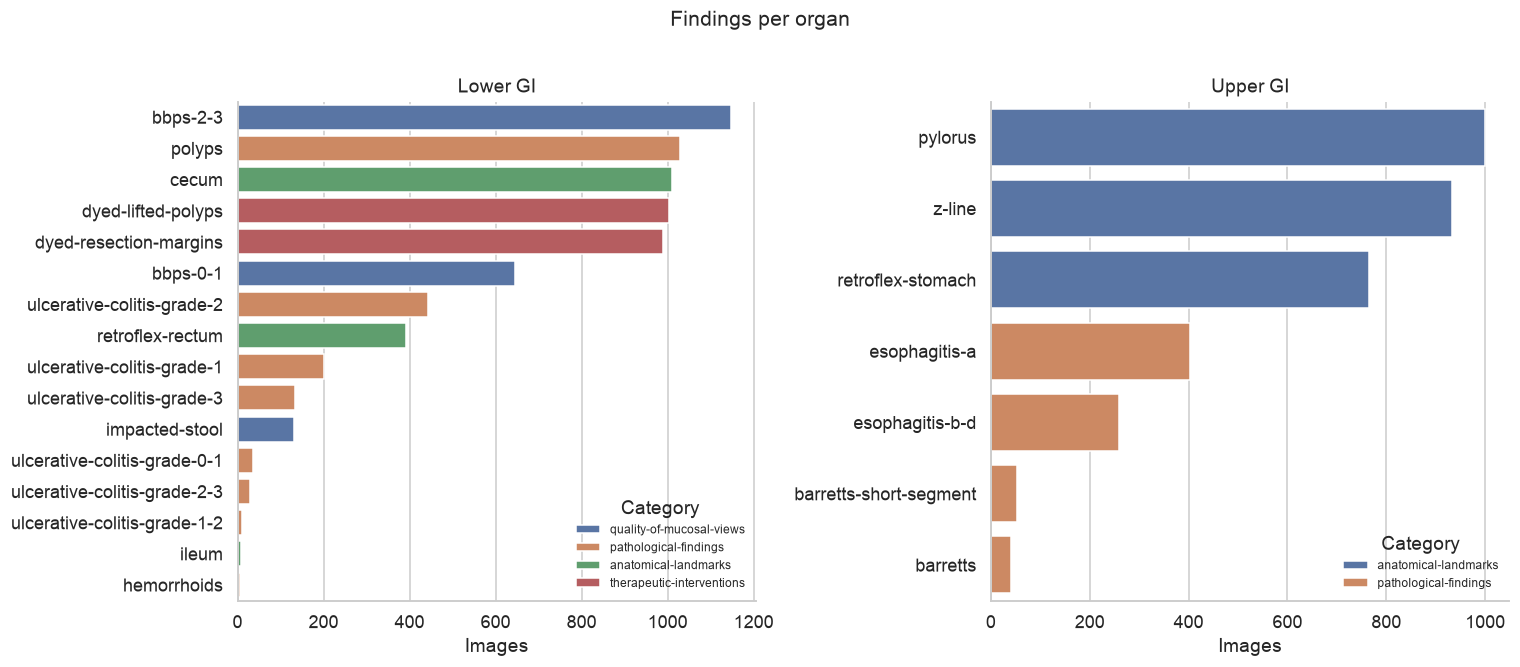

In [11]:
import matplotlib.patches as mpatches
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=False)
for ax, (organ, g) in zip(axes, counts.groupby('organ')):
    sns.barplot(data=g.sort_values('n', ascending=False), y='finding', x='n', hue='category', dodge=False, ax=ax)
    ax.set(title=organ, xlabel='Images', ylabel='')
    ax.legend(title='Category', frameon=False, fontsize=8)
plt.suptitle('Findings per organ', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

## Class imbalance

Largest class: bbps-2-3 (1,148); smallest: hemorrhoids (6)
Imbalance ratio (max/min): 191x
Classes with < 100 images: 7 of 23


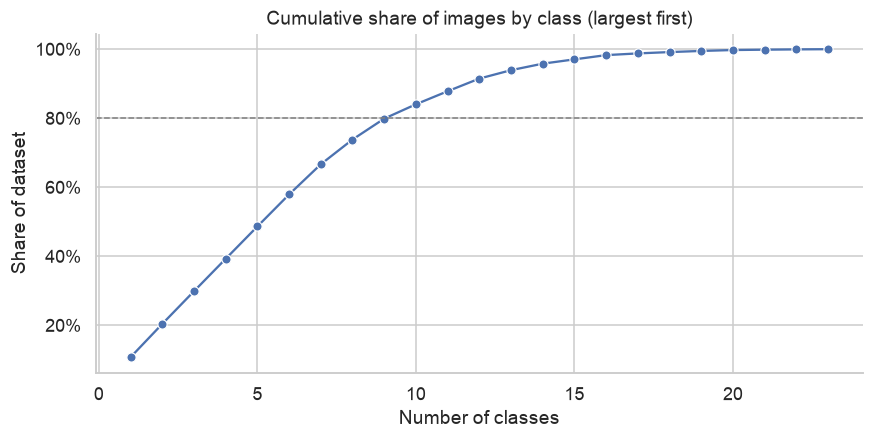

In [12]:
n = counts.set_index('finding').n
print(f'Largest class: {n.idxmax()} ({n.max():,}); smallest: {n.idxmin()} ({n.min()})')
print(f'Imbalance ratio (max/min): {n.max()/n.min():.0f}x')
print(f'Classes with < 100 images: {(n < 100).sum()} of {len(n)}')

cum = n.sort_values(ascending=False).cumsum() / n.sum()
fig, ax = plt.subplots(figsize=(9, 4))
sns.lineplot(x=range(1, len(cum) + 1), y=cum.values, marker='o', ax=ax)
ax.axhline(.8, ls='--', c='grey', lw=1)
ax.set(title='Cumulative share of images by class (largest first)', xlabel='Number of classes', ylabel='Share of dataset')
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.show()

## Takeaways

In [13]:
top = counts.head(5)
print('Lower GI share:', f'{(df.organ == "Lower GI").mean():.0%}')
print('Anatomical landmarks share:', f'{(df.category == "anatomical-landmarks").mean():.0%}')
print('Pathological findings share:', f'{(df.category == "pathological-findings").mean():.0%}')
print('Top 5 findings cover', f'{top.n.sum() / len(df):.0%}', 'of images:', ', '.join(top.finding))

Lower GI share: 68%
Anatomical landmarks share: 38%
Pathological findings share: 25%
Top 5 findings cover 49% of images: bbps-2-3, polyps, cecum, dyed-lifted-polyps, pylorus
